# BEA C7 alkanes: multinomial MPD versus dual-site Langmuir + IAST

Seven C7 isomers (1 % each in helium) in BEA at 552 K. The equilibrium model is the competitive dual-site Langmuir
isotherm of `../langmuir/simulation.json`: one saturation capacity per site family ($q_{\mathrm{sat},1}=1.2$,
$q_{\mathrm{sat},2}=0.4$ mol kg$^{-1}$) shared by all components. The MPD in `../mpd/particle_distribution.data` is the
same model written as a distribution: per site family a multinomial over $N_s$ sites,

$$\Pi_s(\mathbf n)=\frac{N_s!}{\left(N_s-\sum_i n_i\right)!\,\prod_i n_i!}\,
\frac{\prod_i (b_{i,s}f^{\mathrm{ref}})^{n_i}}{\bigl(1+\sum_j b_{j,s}f^{\mathrm{ref}}\bigr)^{N_s}},$$

with $N_1=3$ and $N_2=1$, convolved over the total counts. Ruptura reweights it to every $(f,\mathbf y)$ and reports
$q_i=\langle N_i\rangle/(N_{\mathrm A}m_{\mathrm{fw}})$. The reference is the same dual-site Langmuir isotherm mixed with IAST.

All inputs are generated by `generate.py` and run with `run.py`; this notebook only reads the results.

| directory | contents |
| --- | --- |
| `mixture/iast`, `mixture/mpd` | mixture isotherms, $10^3$ to $10^7$ Pa |
| `variance/mpd_<name>_{minus,plus}` | MPD mixture isotherms with $y_i$ shifted by a relative $\mp 10^{-3}$ against helium |
| `breakthrough/iast`, `breakthrough/mpd` | standard settings of `examples/BEA-alkanes-C7/breakthrough`, SPGMR linear solver |

In [1]:
from pathlib import Path
import json
import re

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, LogNorm
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

AVOGADRO = 6.02214076e23  # mol^-1
MODELS = ("iast", "mpd")
COMPONENTS = ("nC7", "C6m2", "C6m3", "C5m2m2", "C5m2m3", "C5m2m4", "C5m3m3")
COMPONENT_INDEX = {name: index for index, name in enumerate(COMPONENTS, start=1)}
MPD_SETTINGS = json.loads(Path("mixture/mpd/simulation.json").read_text())["MPDSettings"]
FRAMEWORK_MASS = MPD_SETTINGS["ReferenceFrameworkMass"]
PARTICLES_PER_LOADING = AVOGADRO * FRAMEWORK_MASS  # particles per mol/kg in the MPD reference system


def read_mixture(directory, component):
    """Total fugacity [Pa], mixture loading [mol/kg] and gas-phase mole fraction [-] of one component."""
    table = np.loadtxt(Path(directory) / f"component_{COMPONENT_INDEX[component]}_{component}.data", comments="#")
    return {"fugacity": table[:, 0], "loading": table[:, 2], "mole_fraction": table[:, 3]}


def read_outlet(directory, component):
    """Outlet history: time [s] and normalized mole fraction y_i / y_i,0 [-]."""
    simulation = json.loads((Path(directory) / "simulation.json").read_text())
    feed = next(entry["GasPhaseMolFraction"] for entry in simulation["Components"] if entry["Name"] == component)
    table = np.loadtxt(Path(directory) / f"component_{COMPONENT_INDEX[component]}_{component}.data", comments="#")
    outlet = table[np.isclose(table[:, 2], simulation["ColumnLength"])]
    order = np.argsort(outlet[:, 1])
    return {"time": 60.0 * outlet[order, 1], "normalized": outlet[order, 5] / feed}


# Reference distribution Pi_ref(n), C-ordered over the components with the last one varying fastest.
PARTICLE_NUMBERS = {bounds["Component"]: np.arange(bounds["NMin"], bounds["NMax"] + 1, bounds["DeltaN"])
                    for bounds in MPD_SETTINGS["ComponentBounds"]}
distribution = np.loadtxt(Path("mixture/mpd") / MPD_SETTINGS["FileName"], comments="#").reshape(
    [len(PARTICLE_NUMBERS[name]) for name in COMPONENTS])

mixture = {model: {name: read_mixture(f"mixture/{model}", name) for name in COMPONENTS} for model in MODELS}

# Var(N_i) = d<N_i>/d ln f_i at fixed f_j: f_i = y_i p is varied through y_i, the carrier gas absorbs the change.
loading_sigma = {}
for name in COMPONENTS:
    plus = read_mixture(f"variance/mpd_{name}_plus", name)
    minus = read_mixture(f"variance/mpd_{name}_minus", name)
    slope = (plus["loading"] - minus["loading"]) / np.log(plus["mole_fraction"] / minus["mole_fraction"])
    loading_sigma[name] = np.sqrt(slope * PARTICLES_PER_LOADING) / PARTICLES_PER_LOADING

print(f"MPD reference system: m_fw = {FRAMEWORK_MASS:.6e} kg = {PARTICLES_PER_LOADING:.4f} particles per mol/kg")

MPD reference system: m_fw = 4.151348e-24 kg = 2.5000 particles per mol/kg


## Reference particle distribution

`particle_distribution.data` holds $\Pi_{\mathrm{ref}}(\mathbf n)$ on a 7-dimensional grid,
$n_i\in\{0,\dots,4\}$ for every isomer: $5^7=78\,125$ macrostates, of which 295 are populated. The reference state is
552 K with every isomer at $f^{\mathrm{ref}}=10^5$ Pa. Shown here is the 2D marginal of two isomers, summed over the
other five. At most four molecules fit, three on the primary sites and one on the secondary site, so every macrostate with
$n_{\mathrm{nC7}}+n_{\mathrm{C6m2}}>4$ is empty. The tilt of the populated triangle is the competition for those sites.

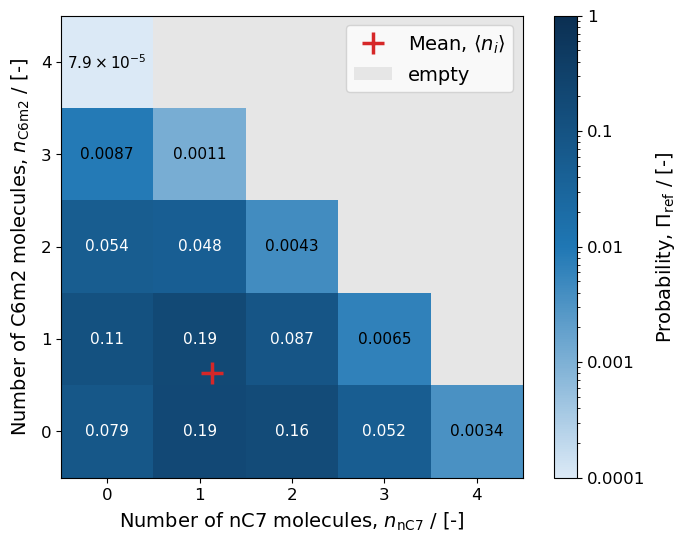

In [2]:
shown = ("nC7", "C6m2")
others = tuple(axis for axis, name in enumerate(COMPONENTS) if name not in shown)
marginal = distribution.sum(axis=others)
if COMPONENTS.index(shown[0]) > COMPONENTS.index(shown[1]):
    marginal = marginal.T
first, second = PARTICLE_NUMBERS[shown[0]], PARTICLE_NUMBERS[shown[1]]
mean = ((marginal.sum(axis=1) * first).sum(), (marginal.sum(axis=0) * second).sum())

colormap = LinearSegmentedColormap.from_list("C0", ["#dbe9f6", "C0", "#0b2f52"])
colormap.set_bad("0.9")
norm = LogNorm(vmin=1e-4, vmax=1.0)

fig, ax = plt.subplots(figsize=(8, 6))
image = ax.pcolormesh(np.append(first - 0.5, first[-1] + 0.5), np.append(second - 0.5, second[-1] + 0.5),
                      np.ma.masked_where(marginal <= 0.0, marginal).T, cmap=colormap, norm=norm)
for i, n_first in enumerate(first):
    for j, n_second in enumerate(second):
        if marginal[i, j] <= 0.0:
            continue
        text = f"{marginal[i, j]:.2g}"
        if "e" in text:
            mantissa, exponent = text.split("e")
            text = rf"${mantissa} \times 10^{{{int(exponent)}}}$"
        ax.text(n_first, n_second, text, ha="center", va="center", fontsize=11,
                color="white" if norm(marginal[i, j]) > 0.6 else "black")
ax.plot(*mean, marker="+", markersize=16, markeredgewidth=2.5, color="C3", linestyle="none",
        label=r"Mean, $\langle n_i\rangle$")
ax.legend(handles=[ax.lines[0], Patch(facecolor="0.9", label="empty")], fontsize=14, loc="upper right")

colorbar = fig.colorbar(image, ax=ax)
colorbar.set_ticks([1e-4, 1e-3, 1e-2, 1e-1, 1.0], labels=["0.0001", "0.001", "0.01", "0.1", "1"])
colorbar.ax.tick_params(labelsize=12)
colorbar.set_label(r"Probability, $\Pi_{\mathrm{ref}}$ / [-]", fontsize=14, labelpad=6.0)

ax.set_aspect("equal")
ax.set_xticks(first)
ax.set_yticks(second)
ax.set_xlabel(rf"Number of {shown[0]} molecules, $n_{{\mathrm{{{shown[0]}}}}}$ / [-]", fontsize=14, labelpad=6.0)
ax.set_ylabel(rf"Number of {shown[1]} molecules, $n_{{\mathrm{{{shown[1]}}}}}$ / [-]", fontsize=14, labelpad=6.0)
ax.tick_params(labelsize=12)
fig.savefig("particle_distribution.pdf", dpi=300, bbox_inches="tight")
plt.show()

## Mixture isotherm

MPD (solid) against dual-site Langmuir + IAST (dashed, open markers), equimolar 1 % feed of every isomer in helium.

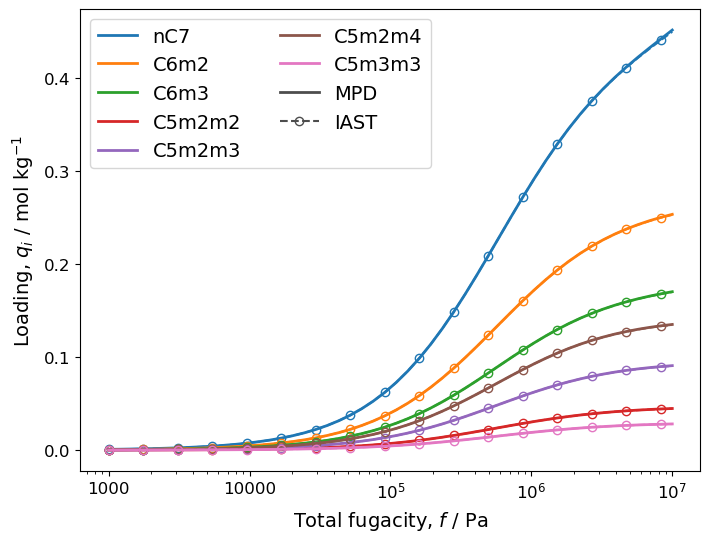

In [3]:
colors = {name: f"C{index}" for index, name in enumerate(COMPONENTS)}

fig, ax = plt.subplots(figsize=(8, 6))
for name in COMPONENTS:
    reference = mixture["iast"][name]
    computed = mixture["mpd"][name]
    ax.plot(reference["fugacity"], reference["loading"], color=colors[name], linestyle="--", marker="o",
            markerfacecolor="none", markevery=3)
    ax.plot(computed["fugacity"], computed["loading"], color=colors[name], linestyle="-", linewidth=2)

handles = [Line2D([0], [0], color=colors[name], linewidth=2, label=name) for name in COMPONENTS]
handles += [
    Line2D([0], [0], color="0.3", linestyle="-", linewidth=2, label="MPD"),
    Line2D([0], [0], color="0.3", linestyle="--", marker="o", markerfacecolor="none", label="IAST"),
]
ax.legend(handles=handles, fontsize=14, ncol=2, loc="upper left")

ax.set_xscale("log")
ax.set_xticks([1e3, 1e4, 1e5, 1e6, 1e7], ["1000", "10000", r"$10^{5}$", r"$10^{6}$", r"$10^{7}$"])
ax.set_xlabel("Total fugacity, $f$ / Pa", fontsize=14, labelpad=6.0)
ax.set_ylabel(r"Loading, $q_i$ / mol kg$^{-1}$", fontsize=14, labelpad=6.0)
ax.tick_params(labelsize=12)
fig.savefig("mixture_isotherm.pdf", dpi=300, bbox_inches="tight")
plt.show()

## Mixture isotherm with its theoretical fluctuations

In the grand-canonical ensemble the slope of the isotherm is the particle-number variance,

$$\frac{\partial\langle N_i\rangle}{\partial f_i}\bigg|_{T,V,f_{j\neq i}}=\frac{\langle N_i^2\rangle-\langle N_i\rangle^2}{f_i}.$$

The derivative has to be taken with respect to the component's own fugacity $f_i=y_ip$, with the other fugacities
held fixed. The slope along total fugacity at fixed composition is the covariance $\langle N_iN\rangle-\langle N_i\rangle\langle N\rangle$
instead. The `variance/` runs therefore shift $y_i$ by a relative $\mp10^{-3}$ against the non-adsorbing helium,
and the derivative is a central difference in $\ln f_i$.

The band is $q_i\pm\sigma_{q,i}$ with $\sigma_{q,i}=\sqrt{\langle N_i^2\rangle-\langle N_i\rangle^2}\,/\,(N_{\mathrm A}m_{\mathrm{fw}})$.
It belongs to the system the MPD represents, $m_{\mathrm{fw}}$ = 4 sites, so the fluctuations are of the order of
the mean. They shrink as $1/\sqrt{m_{\mathrm{fw}}}$ for a larger system, while the isotherm itself does not change.

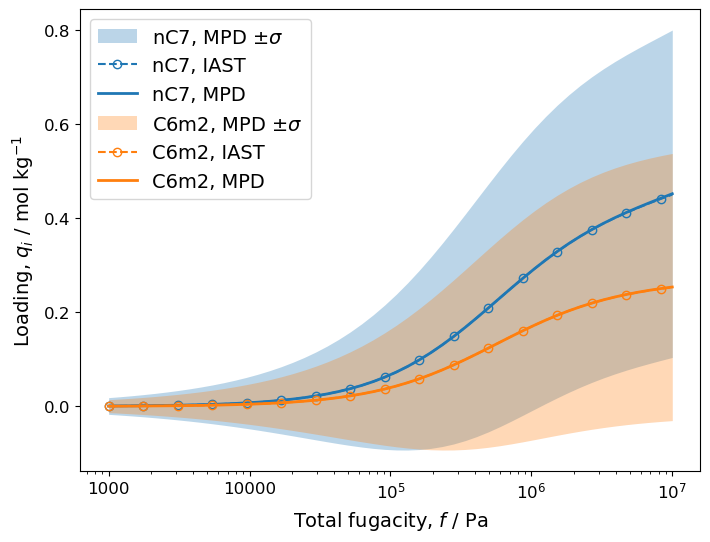

In [4]:
shown = ("nC7", "C6m2")
colors = {name: f"C{index}" for index, name in enumerate(COMPONENTS)}

fig, ax = plt.subplots(figsize=(8, 6))
for name in shown:
    reference = mixture["iast"][name]
    computed = mixture["mpd"][name]
    ax.fill_between(computed["fugacity"], computed["loading"] - loading_sigma[name],
                    computed["loading"] + loading_sigma[name], color=colors[name], alpha=0.3, linewidth=0,
                    label=rf"{name}, MPD $\pm\sigma$")
    ax.plot(reference["fugacity"], reference["loading"], color=colors[name], linestyle="--", marker="o",
            markerfacecolor="none", markevery=3, label=f"{name}, IAST")
    ax.plot(computed["fugacity"], computed["loading"], color=colors[name], linestyle="-", linewidth=2,
            label=f"{name}, MPD")

ax.legend(fontsize=14, loc="upper left")
ax.set_xscale("log")
ax.set_xticks([1e3, 1e4, 1e5, 1e6, 1e7], ["1000", "10000", r"$10^{5}$", r"$10^{6}$", r"$10^{7}$"])
ax.set_xlabel("Total fugacity, $f$ / Pa", fontsize=14, labelpad=6.0)
ax.set_ylabel(r"Loading, $q_i$ / mol kg$^{-1}$", fontsize=14, labelpad=6.0)
ax.tick_params(labelsize=12)
fig.savefig("mixture_isotherm_variance.pdf", dpi=300, bbox_inches="tight")
plt.show()

## Breakthrough

Standard settings of `examples/BEA-alkanes-C7/breakthrough`: 552 K, 1.2 bar inlet, 0.019 m/s, 0.1 m column, CVODE,
100 grid points, `NumberOfTimeSteps: "auto"` with a 1 ms `TimeStep` (the step-based input of RUPTURA 2, now
`SimulationTime: "auto"`; CVODE returned its solution every 1 ms). Only the equilibrium model differs between the two runs,
and both use CVODE's matrix-free SPGMR linear solver instead of the dense finite-difference Jacobian. The timings are
Ruptura's own `Total time`.

In [5]:
total_time_pattern = re.compile(r"^Total time:\s+([0-9.eE+-]+) s$", flags=re.MULTILINE)
final_time_pattern = re.compile(r"^Final time: ([0-9.eE+-]+) \[s\]$", flags=re.MULTILINE)

timings = {}
for model in MODELS:
    log = Path(f"breakthrough/{model}/ruptura.log").read_text()
    simulated = final_time_pattern.findall(log)[-1]
    timings[model] = float(total_time_pattern.findall(log)[-1])
    print(f"{model.upper():4s} breakthrough: {timings[model]:9.1f} s wall ({float(simulated):.0f} s simulated)")
print(f"MPD / IAST: {timings['mpd'] / timings['iast']:.2f}")

IAST breakthrough:     190.3 s wall (1183782 steps, 1184 s simulated)
MPD  breakthrough:    1531.1 s wall (1184150 steps, 1184 s simulated)
MPD / IAST: 8.05


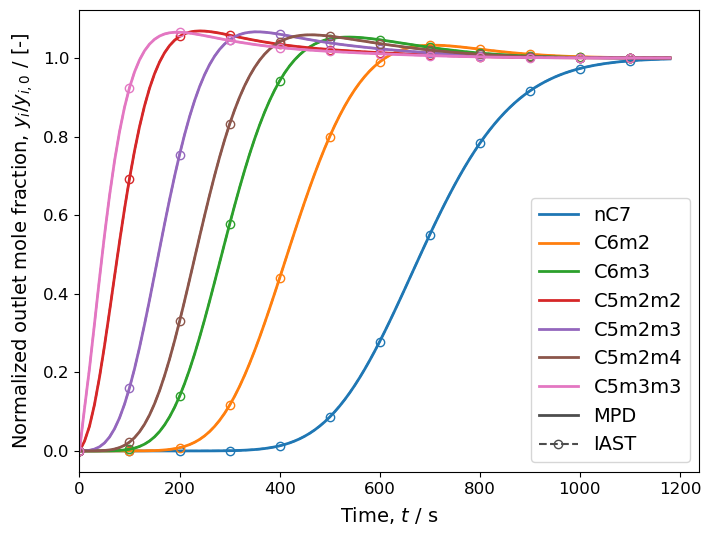

In [6]:
colors = {name: f"C{index}" for index, name in enumerate(COMPONENTS)}

fig, ax = plt.subplots(figsize=(8, 6))
for name in COMPONENTS:
    reference = read_outlet("breakthrough/iast", name)
    computed = read_outlet("breakthrough/mpd", name)
    ax.plot(reference["time"], reference["normalized"], color=colors[name], linestyle="--", marker="o",
            markerfacecolor="none", markevery=10)
    ax.plot(computed["time"], computed["normalized"], color=colors[name], linestyle="-", linewidth=2)

handles = [Line2D([0], [0], color=colors[name], linewidth=2, label=name) for name in COMPONENTS]
handles += [
    Line2D([0], [0], color="0.3", linestyle="-", linewidth=2, label="MPD"),
    Line2D([0], [0], color="0.3", linestyle="--", marker="o", markerfacecolor="none", label="IAST"),
]
ax.legend(handles=handles, fontsize=14, loc="lower right")

ax.set_xlim(left=0.0)
ax.set_xlabel("Time, $t$ / s", fontsize=14, labelpad=6.0)
ax.set_ylabel(r"Normalized outlet mole fraction, $y_i/y_{i,0}$ / [-]", fontsize=14, labelpad=6.0)
ax.tick_params(labelsize=12)
fig.savefig("breakthrough.pdf", dpi=300, bbox_inches="tight")
plt.show()